# 14. Đối chứng với mốc mạnh nhất

Sổ tay notebook 13 cho một kết quả nghịch chiều cần xử lý trước khi viết báo cáo tuần 3. Trên chỉ tiêu sai số tuyệt đối, mô hình tuyến tính neo B huấn luyện bằng hàm bình phương đạt 0,437276 còn mốc trung bình trọng số giảm với `K` bằng năm đạt 0,432919, nghĩa là mốc không tham số thắng với giá trị p bằng 0,026. Đây là lí do thiết kế thử nghiệm bổ sung này.

Giả thuyết giải thích: nghịch chiều sinh ra từ việc so một mô hình tối ưu hóa chỉ tiêu bình phương với một mốc trên chỉ tiêu tuyệt đối, chứ không từ sự yếu kém của họ tuyến tính. Sổ tay notebook 09 cho neo B huấn luyện bằng hàm tuyệt đối đạt sai số tuyệt đối 0,425897, tốt hơn mốc nói trên một khoảng 0,007022. Hai con số đó nằm ở hai sổ tay khác nhau nên hiện chỉ so sánh được điểm, chưa có khoảng tin cậy và chưa có giá trị p.

Câu hỏi cụ thể: khi bắt cặp ở cấp bệnh nhân trên cùng một tập kiểm tra, mô hình tuyến tính neo B huấn luyện bằng hàm tuyệt đối có thắng mốc không tham số mạnh nhất một cách có ý nghĩa thống kê hay không.

Thiết kế: dựng lại họ mốc không tham số bằng đúng định nghĩa của notebook 13, đọc lại tổng sai số theo hồ sơ của hai cấu hình tuyến tính đã có, rồi bắt cặp. Lý do phải dựng lại họ mốc thay vì đọc lại: notebook 13 chỉ ghi chỉ số tổng hợp của các mốc chứ không ghi tổng sai số theo từng hồ sơ, nên không có cách nào bắt cặp từ tệp cũ. Phần dựng lại không cần huấn luyện nên chi phí gần như bằng không. Số lần lấy mẫu lặp đặt ở năm nghìn vì đây là kiểm định quyết định một phát biểu của báo cáo. Chi phí ước lượng khoảng năm phút, phần lớn là thời gian nạp dữ liệu.

> **Vị trí trong chuỗi tái lập:** notebook 14 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 03-Tien_xu_ly_va_thuc_nghiem_chinh, 04-Bon_phuong_an_neo, 09-Ba_ham_mat_mat_hai_neo, 11-Chi_so_theo_nhom_kenh.
>
> **Thư mục kết quả:** `Output/processed/w3_21_doi_chung_moc_manh_nhat/`.
>
> **Mã định danh nội bộ:** `W3_21`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số và đường dẫn

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
READ_TAG = "chot"  #@param {type:"string"}
RUN_TAG = "w3_21_doi_chung_moc_manh_nhat"  #@param {type:"string"}
DANH_SACH_K = "1,2,3,5"  #@param {type:"string"}
HE_SO_GIAM = 0.5  #@param {type:"number"}
NGUON_NEO_B_MAE = "w3_16_ba_ham_mat_mat_hai_neo"  #@param {type:"string"}
NGUON_NEO_B_MSE = "bo_sung_04_neo_abcd"  #@param {type:"string"}
NGUON_NEO_B_MSE_DU_PHONG = "w3_18_chi_so_theo_nhom_kenh"  #@param {type:"string"}
N_BOOT = 5000  #@param {type:"integer"}
SEQ_LEN = 36     #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS = 3      #@param {type:"integer"}
EPOCHS = 60      #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH = 128      #@param {type:"integer"}
LR = 1e-3        #@param {type:"number"}

DANH_K = [int(t) for t in DANH_SACH_K.split(",") if t.strip()]
import os, sys, json, time, random, datetime, platform, importlib, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
OUT = PROJECT / "Output"
# Đọc dữ liệu đã tiền xử lý của lần chạy chốt, ghi kết quả sang một thư mục con riêng.
PROC = OUT / "processed" / READ_TAG
RUN_DIR = OUT / "processed" / RUN_TAG
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (RUN_DIR, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

assert (PROC / "meta.json").exists(), (
    "Không thấy dữ liệu đã tiền xử lý trong " + str(PROC) +
    ". Hãy chạy notebook 03-Tien_xu_ly_va_thuc_nghiem_chinh trước.")
meta = json.loads((PROC / "meta.json").read_text())
channels = meta["channels"]
EPS = 1e-8

print("Thư mục đọc :", PROC)
print("Thư mục ghi :", RUN_DIR)
print("Số kênh     :", len(channels), "| ngưỡng cắt sigma của lần chạy nguồn:", meta["clip_sigma"])


Mounted at /content/drive
Thư mục đọc : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot
Thư mục ghi : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_21_doi_chung_moc_manh_nhat
Số kênh     : 37 | ngưỡng cắt sigma của lần chạy nguồn: 0.0


In [2]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "read_tag": READ_TAG,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
for k, v in ENV.items():
    print(k.ljust(12), v)


timestamp    2026-10-14T18:32:44
run_tag      w3_21_doi_chung_moc_manh_nhat
read_tag     chot
python       3.13.15
numpy        2.1.3
torch        2.11.0+cu130
matplotlib   3.10.0
scipy        1.16.3
gpu          Tesla T4


In [3]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def luu_hinh(fig, ten):
    duong = FIGS / ten
    fig.savefig(duong)
    print("Đã lưu", duong)
    return duong


print("Đã đặt quy ước trình bày hình")


Đã đặt quy ước trình bày hình


## 2. Mô hình, dữ liệu và hàm dùng chung

In [4]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def moving_avg(x, kernel_size=25):
    front = x[:, :1, :].repeat(1, (kernel_size - 1) // 2, 1)
    end = x[:, -1:, :].repeat(1, kernel_size - (kernel_size - 1) // 2 - 1, 1)
    xp = torch.cat([front, x, end], dim=1).permute(0, 2, 1)
    return F.avg_pool1d(xp, kernel_size=kernel_size, stride=1).permute(0, 2, 1)


def last_observed(x, mask):
    # Trả về giá trị quan sát thật gần nhất và số giờ đã trôi qua kể từ phép đo đó.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, -1))
    t_star = idx.max(dim=1).values
    has = t_star >= 0
    val = torch.gather(x, 1, t_star.clamp(min=0).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


def first_observed(x, mask):
    # Trả về giá trị quan sát thật xa nhất trong cửa sổ, dùng cho phép thử đối chứng.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, Lx))
    t_star = idx.min(dim=1).values
    has = t_star < Lx
    val = torch.gather(x, 1, t_star.clamp(max=Lx - 1).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


# Tám định nghĩa neo. Z, A, B, O là neo tĩnh; C, D, E, F có cổng suy giảm học được.
# E và F giống C và D về công thức, chỉ khác điểm khởi tạo của tham số suy giảm.
NEO_HOP_LE = ("Z", "A", "B", "O", "C", "D", "E", "F")
KHOI_TAO_CONG = {"C": 0.0, "D": 0.0, "E": -6.0, "F": -6.0}


class LinearFamily(nn.Module):
    # Một lớp bao trùm cả DLinear và NLinear. Neo áp dụng cho cả hai họ, nên phép so sánh
    # Giữa hai họ và giữa các neo không bị lệch bởi nhánh mã khác nhau.
    def __init__(self, seq_len, pred_len, n_channels, kind="nlinear", anchor="A",
                 use_mask_channel=True, kernel_size=25):
        super().__init__()
        assert kind in ("dlinear", "nlinear")
        assert anchor in NEO_HOP_LE, "Neo không hợp lệ: " + str(anchor)
        self.L, self.H, self.C = seq_len, pred_len, n_channels
        self.kind, self.anchor = kind, anchor
        self.use_mask_channel = use_mask_channel
        self.kernel_size = kernel_size
        in_dim = seq_len * (2 if use_mask_channel else 1)
        if kind == "dlinear":
            self.lin_seasonal = nn.Linear(in_dim, pred_len)
            self.lin_trend = nn.Linear(in_dim, pred_len)
        else:
            self.lin = nn.Linear(in_dim, pred_len)
        if anchor in ("C", "E"):
            self.w_decay = nn.Parameter(torch.full((1,), KHOI_TAO_CONG[anchor]))
        elif anchor in ("D", "F"):
            self.w_decay = nn.Parameter(torch.full((n_channels,), KHOI_TAO_CONG[anchor]))

    def compute_anchor(self, x, mask):
        if self.anchor == "Z":
            return torch.zeros_like(x[:, -1, :])
        if self.anchor == "A":
            return x[:, -1, :]
        if self.anchor == "O":
            val_o, _ = first_observed(x, mask)
            return val_o
        val, dt = last_observed(x, mask)
        if self.anchor == "B":
            return val
        rate = F.softplus(self.w_decay)
        return torch.exp(-rate.view(1, -1) * dt) * val

    def _flatten(self, x, mask):
        B, Lx, C = x.shape
        xt = x.permute(0, 2, 1).reshape(B * C, Lx)
        if not self.use_mask_channel:
            return xt
        mt = mask.permute(0, 2, 1).reshape(B * C, Lx).float()
        return torch.cat([xt, mt], dim=-1)

    def forward(self, x, mask):
        B, Lx, C = x.shape
        a = self.compute_anchor(x, mask)
        xr = x - a.unsqueeze(1)
        if self.kind == "nlinear":
            z = self.lin(self._flatten(xr, mask))
        else:
            trend = moving_avg(xr, self.kernel_size)
            z = self.lin_seasonal(self._flatten(xr - trend, mask)) + \
                self.lin_trend(self._flatten(trend, mask))
        return z.view(B, C, self.H).permute(0, 2, 1) + a.unsqueeze(1)


class Persistence(nn.Module):
    # Đường cơ sở không tham số: giữ nguyên phép đo thật gần nhất cho mọi bước tương lai.
    def __init__(self, pred_len):
        super().__init__()
        self.H = pred_len

    def forward(self, x, mask):
        val, _ = last_observed(x, mask)
        return val.unsqueeze(1).repeat(1, self.H, 1)


def dat_hat_giong(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def tong_theo_ho_so(y_hat, y, m):
    m = m.astype(np.float64)
    se = (m * (y_hat - y) ** 2).reshape(len(m), -1).sum(axis=1)
    ae = (m * np.abs(y_hat - y)).reshape(len(m), -1).sum(axis=1)
    dem = m.reshape(len(m), -1).sum(axis=1)
    return se, ae, dem


def khoang_tin_cay(se, ae, dem, n_boot=2000, seed=0, alpha=0.05):
    # Lấy mẫu lại ở cấp bệnh nhân, không phải cấp điểm đo, vì các điểm trong cùng
    # Một hồ sơ không độc lập với nhau.
    rng = np.random.default_rng(seed)
    N = len(dem)
    mses, maes = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        mses[b] = se[idx].sum() / mau
        maes[b] = ae[idx].sum() / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    return {
        "mse": float(se.sum() / (dem.sum() + EPS)),
        "mse_ci": [float(np.percentile(mses, lo)), float(np.percentile(mses, hi))],
        "mae": float(ae.sum() / (dem.sum() + EPS)),
        "mae_ci": [float(np.percentile(maes, lo)), float(np.percentile(maes, hi))],
        "mae_theo_ho_so": float(np.mean(ae / np.maximum(dem, 1.0))),
    }


print("Thiết bị tính toán:", DEVICE)


Thiết bị tính toán: cuda


In [5]:
def nap_lat(ten, L, H):
    d = np.load(PROC / (ten + ".npz"))
    Xd, Md = d["X"], d["M"]
    assert Xd.shape[1] >= L + H, "Lưới thời gian ngắn hơn L cộng H"
    x, mxx = Xd[:, :L], Md[:, :L]
    y, myy = Xd[:, L:L + H], Md[:, L:L + H]
    giu = myy.reshape(len(myy), -1).sum(axis=1) > 0
    return (torch.from_numpy(x[giu]).float(), torch.from_numpy(mxx[giu]).float(),
            torch.from_numpy(y[giu]).float(), torch.from_numpy(myy[giu]).float(),
            int(giu.sum()), int((~giu).sum()))


SPLITS = {}
for ten in ("train", "val", "test"):
    x, mxx, y, myy, giu, bo = nap_lat(ten, SEQ_LEN, PRED_LEN)
    SPLITS[ten] = TensorDataset(x, mxx, y, myy)
    print(ten.ljust(6), "giữ", giu, "hồ sơ, bỏ", bo, "hồ sơ không có mục tiêu quan sát thật")

N_CH = SPLITS["train"].tensors[0].shape[-1]
print("Số kênh:", N_CH)


train  giữ 5559 hồ sơ, bỏ 41 hồ sơ không có mục tiêu quan sát thật
val    giữ 794 hồ sơ, bỏ 6 hồ sơ không có mục tiêu quan sát thật
test   giữ 1585 hồ sơ, bỏ 15 hồ sơ không có mục tiêu quan sát thật
Số kênh: 37


In [6]:
# Sổ tay tuần 3 cần chính mô hình đã huấn luyện, không chỉ cần chỉ số tổng hợp,
# nên bản này giữ lại mô hình trong bộ nhớ và lưu trọng số ra đĩa.
MO_HINH_DA_HUAN_LUYEN = {}

def tinh_mat_mat(pred, y, m, loai, delta=1.0):
    # Mọi hàm mất mát chỉ tính trên các ô có phép đo thật, mẫu số là tổng mặt nạ.
    if loai == "mse":
        thanh_phan = (pred - y) ** 2
    elif loai == "mae":
        thanh_phan = (pred - y).abs()
    elif loai == "huber":
        thanh_phan = F.huber_loss(pred, y, reduction="none", delta=delta)
    else:
        raise ValueError("Không biết loại mất mát " + str(loai))
    return (m * thanh_phan).sum() / (m.sum() + EPS)


def chay_mot_cau_hinh(kind, anchor="A", seed=0, nhan=None, loai_mat_mat="mse",
                      huber_delta=1.0, epochs=None, patience=None, ghi_file=True,
                      lat=None, thu_muc=None):
    """Huấn luyện một cấu hình, đánh giá trên tập kiểm tra, ghi kết quả ra thư mục runs."""
    epochs = EPOCHS if epochs is None else epochs
    patience = PATIENCE if patience is None else patience
    lat = SPLITS if lat is None else lat
    thu_muc = RUNS if thu_muc is None else thu_muc
    dat_hat_giong(seed)

    if kind == "persistence":
        model = Persistence(PRED_LEN).to(DEVICE)
        so_tham_so = 0
    else:
        model = LinearFamily(SEQ_LEN, PRED_LEN, N_CH, kind=kind, anchor=anchor).to(DEVICE)
        so_tham_so = sum(p.numel() for p in model.parameters() if p.requires_grad)

    loaders = {k: DataLoader(v, batch_size=BATCH, shuffle=(k == "train"))
               for k, v in lat.items()}

    t0 = time.time()
    tot_nhat, trang_thai, xau, lich_su = float("inf"), None, 0, []
    val_mse_luc_tot_nhat = None
    if kind != "persistence":
        opt = torch.optim.Adam(model.parameters(), lr=LR)
        for ep in range(epochs):
            model.train()
            for x, mxx, y, myy in loaders["train"]:
                x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                opt.zero_grad()
                mat_mat = tinh_mat_mat(model(x, mxx), y, myy, loai_mat_mat, huber_delta)
                mat_mat.backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                tu = tu_mse = mau = 0.0
                for x, mxx, y, myy in loaders["val"]:
                    x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                    p = model(x, mxx)
                    if loai_mat_mat == "mse":
                        tp = (p - y) ** 2
                    elif loai_mat_mat == "mae":
                        tp = (p - y).abs()
                    else:
                        tp = F.huber_loss(p, y, reduction="none", delta=huber_delta)
                    tu += float((myy * tp).sum())
                    tu_mse += float((myy * (p - y) ** 2).sum())
                    mau += float(myy.sum())
                val_loss = tu / (mau + EPS)
                val_mse = tu_mse / (mau + EPS)
            lich_su.append(val_loss)
            # Dừng sớm theo đúng hàm mất mát đang huấn luyện, để phép so sánh không thiên lệch.
            if val_loss < tot_nhat - 1e-6:
                tot_nhat, xau, val_mse_luc_tot_nhat = val_loss, 0, val_mse
                trang_thai = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                xau += 1
                if xau >= patience:
                    break
        if trang_thai is not None:
            model.load_state_dict(trang_thai)
    thoi_gian = time.time() - t0

    model.eval()
    du_bao = []
    with torch.no_grad():
        for x, mxx, y, myy in loaders["test"]:
            du_bao.append(model(x.to(DEVICE), mxx.to(DEVICE)).cpu().numpy())
    yhat = np.concatenate(du_bao)
    y_te = lat["test"].tensors[2].numpy()
    my_te = lat["test"].tensors[3].numpy()
    se, ae, dem = tong_theo_ho_so(yhat, y_te, my_te)
    ket = khoang_tin_cay(se, ae, dem, seed=seed)

    ten = nhan or (kind + "_neo" + anchor + "_" + loai_mat_mat + "_s" + str(seed))
    payload = {"name": ten, "kind": kind, "anchor": anchor, "seed": seed,
               "loai_mat_mat": loai_mat_mat, "huber_delta": huber_delta,
               "seq_len": SEQ_LEN, "pred_len": PRED_LEN, "n_params": so_tham_so,
               "protocol": meta["protocol"], "read_tag": READ_TAG, "run_tag": RUN_TAG,
               "val_loss": tot_nhat if tot_nhat < float("inf") else None,
               "val_mse_obs": val_mse_luc_tot_nhat,
               "train_time_sec": round(thoi_gian, 2), "device": DEVICE,
               "history": lich_su, "test": ket, "env": ENV}
    if ghi_file:
        thu_muc.mkdir(parents=True, exist_ok=True)
        (thu_muc / (ten + ".json")).write_text(json.dumps(payload, ensure_ascii=False, indent=2))
        np.savez_compressed(thu_muc / (ten + "_patient_sums.npz"), se=se, ae=ae, n=dem)
    print(ten.ljust(32), "MSE_obs", round(ket["mse"], 4), "| MAE_obs", round(ket["mae"], 4),
          "|", int(thoi_gian), "giây |", so_tham_so, "tham số")
    MO_HINH_DA_HUAN_LUYEN[ten] = model
    if ghi_file and kind != "persistence":
        torch.save(model.state_dict(), thu_muc / (ten + ".pt"))
    return payload


print("Đã định nghĩa hàm huấn luyện")


Đã định nghĩa hàm huấn luyện


In [7]:
def hieu_so_bat_cap(se_a, ae_a, se_b, ae_b, dem, n_boot=2000, seed=0, alpha=0.05):
    """Khoảng tin cậy cho hiệu số hai mô hình, lấy mẫu lại cùng một danh sách bệnh nhân."""
    rng = np.random.default_rng(seed)
    N = len(dem)
    d_mse, d_mae = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        d_mse[b] = (se_a[idx].sum() - se_b[idx].sum()) / mau
        d_mae[b] = (ae_a[idx].sum() - ae_b[idx].sum()) / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    mau_that = dem.sum() + EPS
    return {
        "hieu_mse": float((se_a.sum() - se_b.sum()) / mau_that),
        "hieu_mse_ci": [float(np.percentile(d_mse, lo)), float(np.percentile(d_mse, hi))],
        "hieu_mae": float((ae_a.sum() - ae_b.sum()) / mau_that),
        "hieu_mae_ci": [float(np.percentile(d_mae, lo)), float(np.percentile(d_mae, hi))],
        "p_hai_phia_mse": float(2 * min((d_mse <= 0).mean(), (d_mse >= 0).mean())),
        "p_hai_phia_mae": float(2 * min((d_mae <= 0).mean(), (d_mae >= 0).mean())),
        "mau_bootstrap_mse": d_mse,
        "mau_bootstrap_mae": d_mae,
    }


print("Đã định nghĩa hàm kiểm định bắt cặp")


Đã định nghĩa hàm kiểm định bắt cặp


In [8]:
# Đọc tổng sai số theo từng hồ sơ của nhiều tệp rồi lấy trung bình qua các hạt giống.
# Lấy trung bình trước khi bắt cặp, vì biến thiên do hạt giống không phải đối tượng cần đo.
def nap_tong_tu_danh_sach(danh_sach_tep):
    ses, aes, dem = [], [], None
    for t in danh_sach_tep:
        t = Path(t)
        assert t.exists(), "Không thấy " + str(t)
        d = np.load(t)
        if dem is None:
            dem = d["n"].astype(np.float64)
        ses.append(d["se"].astype(np.float64))
        aes.append(d["ae"].astype(np.float64))
    return np.mean(ses, axis=0), np.mean(aes, axis=0), dem


print("Đã định nghĩa hàm đọc tổng sai số theo hồ sơ")


Đã định nghĩa hàm đọc tổng sai số theo hồ sơ


In [9]:
# Mot ham du bao duy nhat cho moi phep phan tich chi tiet.
def du_bao_tap_kiem_tra(model):
    model.eval()
    phan = []
    with torch.no_grad():
        for x, mxx, y, myy in DataLoader(SPLITS["test"], batch_size=BATCH, shuffle=False):
            phan.append(model(x.to(DEVICE), mxx.to(DEVICE)).cpu().numpy())
    return np.concatenate(phan).astype(np.float64)


Y_TEST = SPLITS["test"].tensors[2].numpy().astype(np.float64)
M_TEST = SPLITS["test"].tensors[3].numpy().astype(np.float64)
X_TEST = SPLITS["test"].tensors[0].numpy().astype(np.float64)
MX_TEST = SPLITS["test"].tensors[1].numpy().astype(np.float64)
print("Tập kiểm tra:", Y_TEST.shape[0], "hồ sơ |", int(M_TEST.sum()), "điểm quan sát thật")


Tập kiểm tra: 1585 hồ sơ | 136752 điểm quan sát thật


In [10]:
# Định nghĩa họ mốc trung bình dịch chuyển được lặp lại nguyên văn từ notebook 13,
# Để hai sổ tay dùng cùng một công thức chứ không có hai nhánh mã song song.
# Phép trung bình chỉ lấy trên ô có phép đo thật, không lấy trên ô đã điền không.
def du_bao_trung_binh(K, trong_so_giam=False, he_so=0.5):
    N, L, C = X_TEST.shape
    diem = np.where(MX_TEST > 0, np.arange(1, L + 1).reshape(1, L, 1), 0)
    thu_tu = np.argsort(-diem, axis=1)[:, :K, :]
    gia_tri = np.take_along_axis(X_TEST, thu_tu, axis=1)
    hop_le = np.take_along_axis(diem, thu_tu, axis=1) > 0
    if trong_so_giam:
        w = (he_so ** np.arange(K, dtype=np.float64)).reshape(1, K, 1)
    else:
        w = np.ones((1, K, 1), dtype=np.float64)
    w = w * hop_le
    tong_w = w.sum(axis=1)
    neo = np.where(tong_w > 0, (w * gia_tri).sum(axis=1) / np.maximum(tong_w, EPS), 0.0)
    return np.repeat(neo[:, None, :], PRED_LEN, axis=1)


def danh_gia_du_bao(yhat, nhan, seed=0):
    se, ae, dem = tong_theo_ho_so(yhat, Y_TEST, M_TEST)
    kq = khoang_tin_cay(se, ae, dem, n_boot=N_BOOT, seed=seed)
    print(nhan.ljust(34), "MSE", round(kq["mse"], 6), "| MAE", round(kq["mae"], 6))
    return {"nhan": nhan, "chi_so": kq, "se": se, "ae": ae, "dem": dem}


print("Đã định nghĩa họ mốc trung bình dịch chuyển")


Đã định nghĩa họ mốc trung bình dịch chuyển


## 3. Dựng lại họ mốc không tham số

Đường cơ sở Persistence được chạy lại để sổ tay tự chứa khi tính chỉ số kỹ năng. Phép tự kiểm tra cài sẵn vẫn giữ nguyên: mốc trung bình đều với `K` bằng một phải trùng Persistence, vì hai định nghĩa khi đó đồng nhất về toán học. Con số in ra ở bước này phải khớp từng chữ số với bảng của notebook 13, đó là điều kiện ghép dữ liệu giữa hai sổ tay.

In [11]:
t0 = time.time()
p_per = chay_mot_cau_hinh("persistence", seed=0, nhan="persistence_luoi")
MAE_PERSISTENCE = float(p_per["test"]["mae"])
MSE_PERSISTENCE = float(p_per["test"]["mse"])

MOC = {}
for K in DANH_K:
    MOC["deu_K" + str(K)] = danh_gia_du_bao(
        du_bao_trung_binh(K), "trung bình đều K bằng " + str(K))
for K in DANH_K:
    if K == 1:
        continue
    MOC["giam_K" + str(K)] = danh_gia_du_bao(
        du_bao_trung_binh(K, trong_so_giam=True, he_so=HE_SO_GIAM),
        "trọng số giảm K bằng " + str(K))

lech = abs(MOC["deu_K1"]["chi_so"]["mse"] - MSE_PERSISTENCE)
print("Sai lệch giữa K bằng một và Persistence:", round(float(lech), 10))
assert lech < 1e-8, "Họ trung bình dịch chuyển không khớp Persistence tại K bằng một"
print("Tổng thời gian:", round((time.time() - t0) / 60, 1), "phút")


persistence_luoi                 MSE_obs 0.5788 | MAE_obs 0.4659 | 0 giây | 0 tham số
trung bình đều K bằng 1            MSE 0.578754 | MAE 0.465943
trung bình đều K bằng 2            MSE 0.508556 | MAE 0.446067
trung bình đều K bằng 3            MSE 0.486649 | MAE 0.439777
trung bình đều K bằng 5            MSE 0.478007 | MAE 0.440572
trọng số giảm K bằng 2             MSE 0.511364 | MAE 0.444744
trọng số giảm K bằng 3             MSE 0.48991 | MAE 0.43732
trọng số giảm K bằng 5             MSE 0.476962 | MAE 0.432919
Sai lệch giữa K bằng một và Persistence: 2e-10
Tổng thời gian: 0.0 phút


## 4. Đọc lại hai cấu hình tuyến tính

Cấu hình thứ nhất là neo B huấn luyện bằng hàm tuyệt đối, lấy từ notebook 09. Cấu hình thứ hai là neo B huấn luyện bằng hàm bình phương, lấy từ lần chạy tuần 2 và có thư mục dự phòng của notebook 11 nếu thư mục chính thiếu tệp. Cả hai được đọc ở dạng tổng sai số theo hồ sơ rồi lấy trung bình qua các hạt giống, đúng quy ước đã dùng từ tuần 2. Nếu không tìm thấy tệp nào, sổ tay tự huấn luyện bù để vẫn chạy độc lập được.

In [12]:
SEEDS = list(range(N_SEEDS))


def doc_hoac_huan_luyen(ten_cau_hinh, ung_vien, neo, mat_mat):
    for thu_muc_ten, tien_to in ung_vien:
        thu_muc = OUT / "processed" / thu_muc_ten / "runs"
        tep = [thu_muc / (tien_to + "_s" + str(s) + "_patient_sums.npz") for s in SEEDS]
        if all(t.exists() for t in tep):
            se, ae, dem = nap_tong_tu_danh_sach(tep)
            print("Đọc lại", ten_cau_hinh, "từ", thu_muc_ten)
            return se, ae, dem, thu_muc_ten
    print("Không thấy kết quả cũ cho", ten_cau_hinh, "nên huấn luyện mới")
    for s in SEEDS:
        chay_mot_cau_hinh("nlinear", anchor=neo, seed=s, loai_mat_mat=mat_mat,
                          nhan="nlinear_neo" + neo + "_" + mat_mat + "_s" + str(s))
    tep = [RUNS / ("nlinear_neo" + neo + "_" + mat_mat + "_s" + str(s) + "_patient_sums.npz")
           for s in SEEDS]
    se, ae, dem = nap_tong_tu_danh_sach(tep)
    return se, ae, dem, RUN_TAG


se_mae, ae_mae, dem_mae, nguon_mae = doc_hoac_huan_luyen(
    "neo B với hàm tuyệt đối",
    [(NGUON_NEO_B_MAE, "nlinear_neoB_mae")], "B", "mae")
se_mse, ae_mse, dem_mse, nguon_mse = doc_hoac_huan_luyen(
    "neo B với hàm bình phương",
    [(NGUON_NEO_B_MSE, "nlinear_neoB"),
     (NGUON_NEO_B_MSE_DU_PHONG, "nlinear_neoB_mse")], "B", "mse")

TUYEN_TINH = {
    "neoB_mae": {"se": se_mae, "ae": ae_mae, "dem": dem_mae, "nguon": nguon_mae,
                 "nhan": "tuyến tính neo B, hàm tuyệt đối"},
    "neoB_mse": {"se": se_mse, "ae": ae_mse, "dem": dem_mse, "nguon": nguon_mse,
                 "nhan": "tuyến tính neo B, hàm bình phương"},
}
for khoa, g in TUYEN_TINH.items():
    g["mse"] = float(g["se"].sum() / (g["dem"].sum() + EPS))
    g["mae"] = float(g["ae"].sum() / (g["dem"].sum() + EPS))
    print(khoa.ljust(10), "MSE", round(g["mse"], 6), "| MAE", round(g["mae"], 6))


Đọc lại neo B với hàm tuyệt đối từ w3_16_ba_ham_mat_mat_hai_neo
Đọc lại neo B với hàm bình phương từ bo_sung_04_neo_abcd
neoB_mae   MSE 0.438417 | MAE 0.425897
neoB_mse   MSE 0.436036 | MAE 0.437276


In [13]:
# Điều kiện ghép dữ liệu: hai cấu hình phải cùng số hồ sơ và cùng tổng số điểm mục tiêu
# Với họ mốc, nếu không thì phép bắt cặp theo bệnh nhân không hợp lệ.
dem_moc = MOC["deu_K1"]["dem"]
for khoa, g in TUYEN_TINH.items():
    assert len(g["dem"]) == len(dem_moc), "Số hồ sơ không khớp ở " + khoa
    assert abs(float(g["dem"].sum() - dem_moc.sum())) < 1e-6, \
        "Tổng số điểm mục tiêu không khớp ở " + khoa
print("Điều kiện ghép dữ liệu đã thỏa mãn trên", len(dem_moc), "hồ sơ")


Điều kiện ghép dữ liệu đã thỏa mãn trên 1585 hồ sơ


## 5. Bắt cặp từng mốc với từng cấu hình tuyến tính

Hiệu số được định nghĩa là mô hình tuyến tính trừ mốc, nên giá trị âm có nghĩa mô hình tốt hơn. Phép bắt cặp dùng cùng một danh sách bệnh nhân cho cả hai phía, nên biến thiên do thành phần bệnh nhân bị khử bớt và khoảng tin cậy hẹp hơn nhiều so với khoảng của từng giá trị tuyệt đối. Kết luận so sánh phải đọc trên khoảng của hiệu, không đọc trên khoảng của từng giá trị.

In [14]:
SO_SANH = {}
for ten_mo_hinh, g in TUYEN_TINH.items():
    for khoa, goi in MOC.items():
        kq = hieu_so_bat_cap(g["se"], g["ae"], goi["se"], goi["ae"], g["dem"],
                             n_boot=N_BOOT, seed=0)
        SO_SANH[ten_mo_hinh + "_tru_" + khoa] = {
            "mo_hinh": g["nhan"], "moc": goi["nhan"],
            "mse_mo_hinh": g["mse"], "mae_mo_hinh": g["mae"],
            "mse_moc": goi["chi_so"]["mse"], "mae_moc": goi["chi_so"]["mae"],
            "hieu_mse": kq["hieu_mse"], "hieu_mse_ci": kq["hieu_mse_ci"],
            "p_mse": kq["p_hai_phia_mse"],
            "hieu_mae": kq["hieu_mae"], "hieu_mae_ci": kq["hieu_mae_ci"],
            "p_mae": kq["p_hai_phia_mae"],
        }
        print((ten_mo_hinh + " trừ " + khoa).ljust(26),
              "hiệu MAE", round(kq["hieu_mae"], 6), kq["hieu_mae_ci"],
              "p", round(kq["p_hai_phia_mae"], 4))


neoB_mae trừ deu_K1        hiệu MAE -0.040046 [-0.04506752228147057, -0.03533359637418117] p 0.0
neoB_mae trừ deu_K2        hiệu MAE -0.02017 [-0.02427146736950702, -0.016311961606292877] p 0.0
neoB_mae trừ deu_K3        hiệu MAE -0.01388 [-0.017658837720942667, -0.010174580822910362] p 0.0
neoB_mae trừ deu_K5        hiệu MAE -0.014674 [-0.0180950322316711, -0.011171961994950227] p 0.0
neoB_mae trừ giam_K2       hiệu MAE -0.018847 [-0.0227259237503415, -0.01514406695855708] p 0.0
neoB_mae trừ giam_K3       hiệu MAE -0.011423 [-0.014894655791828247, -0.008100673141030655] p 0.0
neoB_mae trừ giam_K5       hiệu MAE -0.007022 [-0.010072709959415626, -0.0040520027612226065] p 0.0
neoB_mse trừ deu_K1        hiệu MAE -0.028668 [-0.034580745948188336, -0.023010673021705185] p 0.0
neoB_mse trừ deu_K2        hiệu MAE -0.008792 [-0.013485730357997919, -0.004226571481386302] p 0.0
neoB_mse trừ deu_K3        hiệu MAE -0.002502 [-0.006710713384210929, 0.0017076847954314801] p 0.2412
neoB_mse trừ deu

In [15]:
# Câu trả lời trực tiếp cho câu hỏi của sổ tay: lấy mốc mạnh nhất theo sai số tuyệt đối
# Rồi đọc kết quả bắt cặp với cấu hình tốt nhất theo cùng chỉ tiêu.
moc_manh_nhat_mae = min(MOC, key=lambda k: MOC[k]["chi_so"]["mae"])
moc_manh_nhat_mse = min(MOC, key=lambda k: MOC[k]["chi_so"]["mse"])
print("Mốc mạnh nhất theo sai số tuyệt đối :", MOC[moc_manh_nhat_mae]["nhan"],
      round(MOC[moc_manh_nhat_mae]["chi_so"]["mae"], 6))
print("Mốc mạnh nhất theo sai số bình phương:", MOC[moc_manh_nhat_mse]["nhan"],
      round(MOC[moc_manh_nhat_mse]["chi_so"]["mse"], 6))

then = SO_SANH["neoB_mae_tru_" + moc_manh_nhat_mae]
cu = SO_SANH["neoB_mse_tru_" + moc_manh_nhat_mae]
print("Phát biểu cũ, mô hình huấn luyện bằng hàm bình phương: hiệu MAE",
      round(cu["hieu_mae"], 6), "p", round(cu["p_mae"], 4))
print("Phát biểu mới, mô hình huấn luyện bằng hàm tuyệt đối : hiệu MAE",
      round(then["hieu_mae"], 6), "p", round(then["p_mae"], 4))
if then["hieu_mae"] < 0 and then["p_mae"] < 0.05:
    KET_LUAN = "Mô hình tuyến tính thắng mốc mạnh nhất trên cả hai chỉ tiêu"
elif then["hieu_mae"] < 0:
    KET_LUAN = "Mô hình tuyến tính nhỉnh hơn nhưng chưa đạt ý nghĩa thống kê"
else:
    KET_LUAN = "Mốc không tham số vẫn thắng trên sai số tuyệt đối"
print("Kết luận:", KET_LUAN)


Mốc mạnh nhất theo sai số tuyệt đối : trọng số giảm K bằng 5 0.432919
Mốc mạnh nhất theo sai số bình phương: trọng số giảm K bằng 5 0.476962
Phát biểu cũ, mô hình huấn luyện bằng hàm bình phương: hiệu MAE 0.004357 p 0.0264
Phát biểu mới, mô hình huấn luyện bằng hàm tuyệt đối : hiệu MAE -0.007022 p 0.0
Kết luận: Mô hình tuyến tính thắng mốc mạnh nhất trên cả hai chỉ tiêu


## 6. Hình đối chứng

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_21_doi_chung_moc_manh_nhat/figures/W3_21_doi_chung_moc_manh_nhat.png


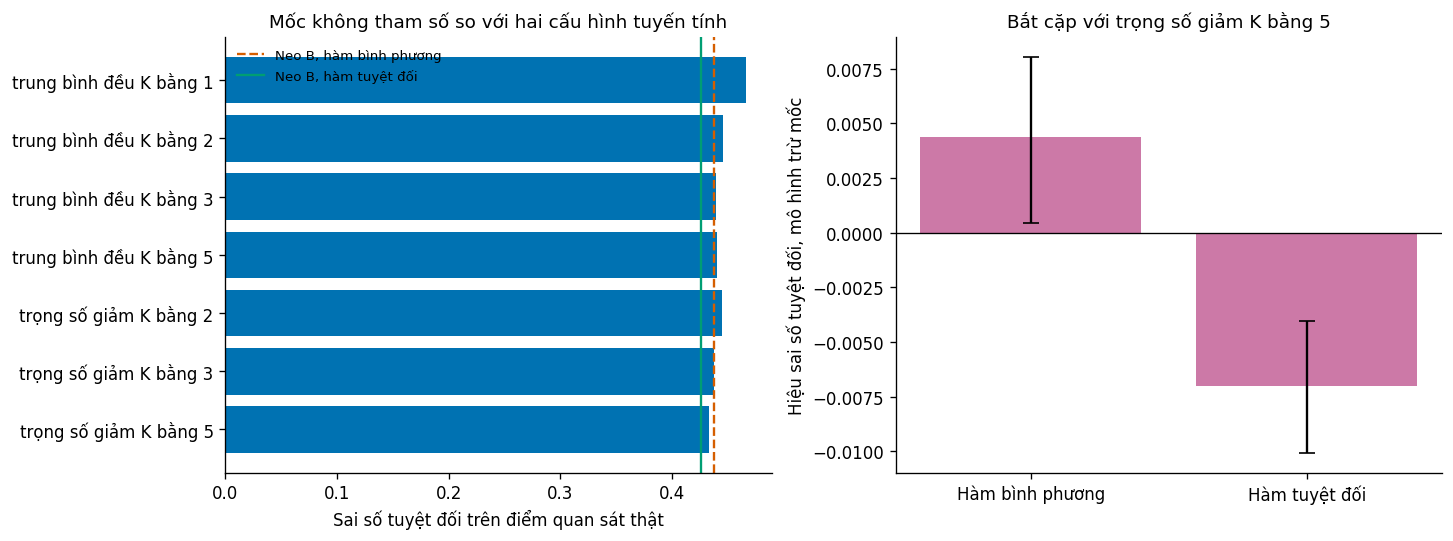

In [16]:
ten = list(MOC)
nhan = [MOC[t]["nhan"] for t in ten]
mae_moc = [MOC[t]["chi_so"]["mae"] for t in ten]
vi_tri = np.arange(len(ten))

fig, ax = plt.subplots(1, 2, figsize=(12.0, 4.4))
ax[0].barh(vi_tri, mae_moc, color=PALETTE[0])
ax[0].axvline(TUYEN_TINH["neoB_mse"]["mae"], color=PALETTE[1], linestyle="--",
              label="Neo B, hàm bình phương")
ax[0].axvline(TUYEN_TINH["neoB_mae"]["mae"], color=PALETTE[2], linestyle="-",
              label="Neo B, hàm tuyệt đối")
ax[0].set_yticks(vi_tri)
ax[0].set_yticklabels(nhan)
ax[0].invert_yaxis()
ax[0].set_xlabel("Sai số tuyệt đối trên điểm quan sát thật")
ax[0].set_title("Mốc không tham số so với hai cấu hình tuyến tính")
ax[0].legend(fontsize=8)

cap = ["neoB_mse_tru_" + moc_manh_nhat_mae, "neoB_mae_tru_" + moc_manh_nhat_mae]
nhan_cap = ["Hàm bình phương", "Hàm tuyệt đối"]
gia = [SO_SANH[k]["hieu_mae"] for k in cap]
ci = [SO_SANH[k]["hieu_mae_ci"] for k in cap]
duoi = [g - x[0] for g, x in zip(gia, ci)]
tren = [x[1] - g for g, x in zip(gia, ci)]
ax[1].bar(nhan_cap, gia, yerr=[duoi, tren], color=PALETTE[3], capsize=5)
ax[1].axhline(0.0, color="black", linewidth=0.8)
ax[1].set_ylabel("Hiệu sai số tuyệt đối, mô hình trừ mốc")
ax[1].set_title("Bắt cặp với " + MOC[moc_manh_nhat_mae]["nhan"])
luu_hinh(fig, "W3_21_doi_chung_moc_manh_nhat.png")
plt.show()


## 7. Ghi kết quả

In [17]:
ket_qua = {
    "kiem_tra_luc": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG, "read_tag": READ_TAG, "n_seeds": N_SEEDS,
    "n_boot": N_BOOT, "danh_sach_k": DANH_K, "he_so_giam": HE_SO_GIAM,
    "mse_persistence": MSE_PERSISTENCE, "mae_persistence": MAE_PERSISTENCE,
    "nguon_tuyen_tinh": {k: g["nguon"] for k, g in TUYEN_TINH.items()},
    "chi_so_tuyen_tinh": {k: {"mse": g["mse"], "mae": g["mae"]}
                          for k, g in TUYEN_TINH.items()},
    "chi_so_moc": {k: g["chi_so"] for k, g in MOC.items()},
    "moc_manh_nhat_mae": moc_manh_nhat_mae,
    "moc_manh_nhat_mse": moc_manh_nhat_mse,
    "so_sanh": SO_SANH,
    "ket_luan": KET_LUAN,
}
dich = RUN_DIR / "W3_doi_chung_moc_manh_nhat.json"
dich.write_text(json.dumps(ket_qua, ensure_ascii=False, indent=2))
print("Đã ghi", dich)


Đã ghi /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_21_doi_chung_moc_manh_nhat/W3_doi_chung_moc_manh_nhat.json
